In [ ]:
All Yields Reported

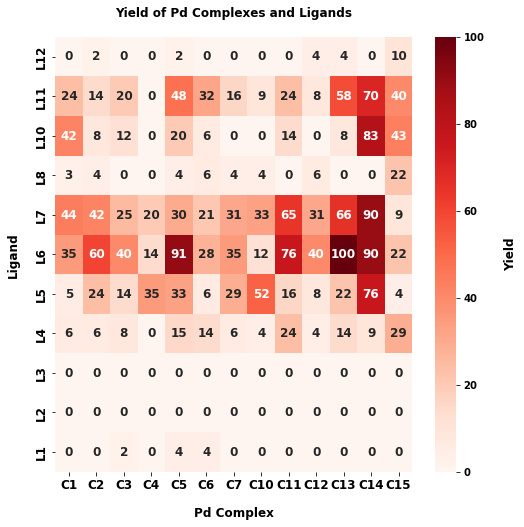

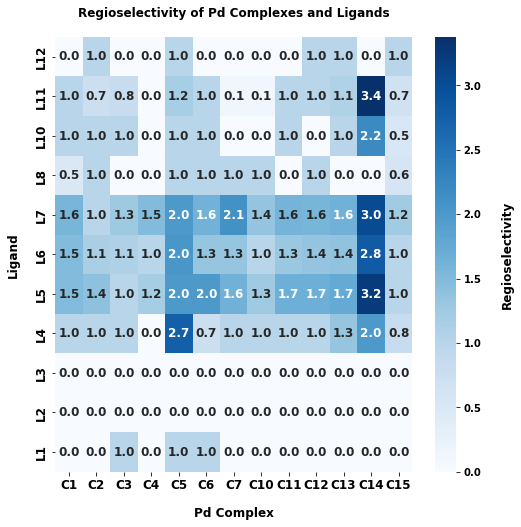

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Excel file
file_path = 'Substrate 1.xlsx'  # Replace with your file path
df = pd.read_excel(file_path)

# Extracting numeric part and sorting
df['Ligand_num'] = df['Ligand'].str.extract('(\d+)').astype(int)
df['Pd_Complex_num'] = df['Pd Complex'].str.extract('(\d+)').astype(int)
df.sort_values(['Ligand_num', 'Pd_Complex_num'], ascending=[False, True], inplace=True)

# Function to create and save a heatmap for a given column
def create_heatmap(data, column, title, color, fmt, file_name):
    pivot_table = data.pivot("Ligand", "Pd Complex", column).reindex(index=df['Ligand'].unique(), columns=df['Pd Complex'].unique())
    plt.figure(figsize=(8, 8))  # Adjust size for square boxes
    ax = sns.heatmap(pivot_table, annot=True, fmt=fmt, cmap=color, 
                     annot_kws={'weight': 'bold', 'size': 12}, cbar_kws={'label': column})
    ax.set_title(title, weight='bold', pad=20, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), weight='bold', labelpad=15, fontsize=12)
    ax.set_ylabel(ax.get_ylabel(), weight='bold', labelpad=15, fontsize=12)
    
    ax.set_xticklabels(ax.get_xticklabels(), weight='bold', fontsize=12)
    ax.set_yticklabels(ax.get_yticklabels(), weight='bold', fontsize=12)

    cbar = ax.collections[0].colorbar
    cbar.ax.set_ylabel(cbar.ax.get_ylabel(), weight='bold', fontsize=12, labelpad=20)
    for label in cbar.ax.yaxis.get_ticklabels():
        label.set_weight('bold')
        label.set_size(10)

    # Save the figure as a high-resolution image
    plt.savefig(file_name, dpi=500, bbox_inches='tight')
    plt.show()

# Create and save heatmap for Yield
create_heatmap(df, "Yield", "Yield of Pd Complexes and Ligands", "Reds", "d", "yield_heatmap.png")

# Create and save heatmap for Regioselectivity
create_heatmap(df, "Regioselectivity", "Regioselectivity of Pd Complexes and Ligands", "Blues", ".1f", "regioselectivity_heatmap.png")



In [ ]:
Remove all 0 percent yields

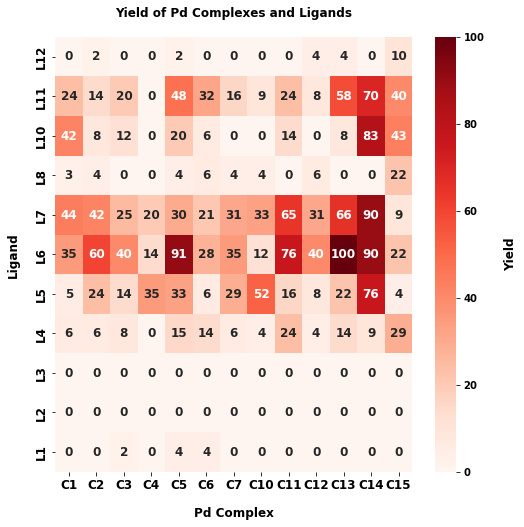

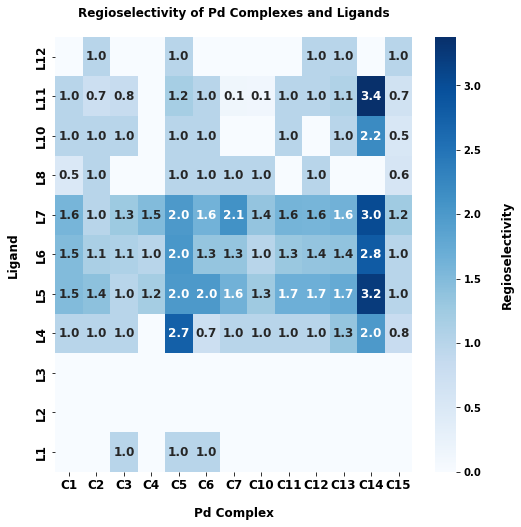

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load the Excel file
file_path = 'Pd_HTE1.xlsx'  # Replace with your file path
df = pd.read_excel(file_path)

# Extracting numeric part and sorting
df['Ligand_num'] = df['Ligand'].str.extract('(\d+)').astype(int)
df['Pd_Complex_num'] = df['Pd Complex'].str.extract('(\d+)').astype(int)
df.sort_values(['Ligand_num', 'Pd_Complex_num'], ascending=[False, True], inplace=True)

def custom_annot(val, column):
    if column == "Regioselectivity" and (val == 0 or np.isnan(val)):
        return ''
    elif column == "Yield":
        return f'{val:.0f}'
    else:
        return f'{val:.1f}'

def create_heatmap(data, column, title, color, file_name):
    pivot_table = data.pivot("Ligand", "Pd Complex", column).reindex(index=df['Ligand'].unique(), columns=df['Pd Complex'].unique())
    plt.figure(figsize=(8, 8))
    ax = sns.heatmap(pivot_table, annot=True, fmt="", cmap=color, 
                     annot_kws={'weight': 'bold', 'size': 12}, cbar_kws={'label': column},
                     cbar=True)
    ax.set_title(title, weight='bold', pad=20, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), weight='bold', labelpad=15, fontsize=12)
    ax.set_ylabel(ax.get_ylabel(), weight='bold', labelpad=15, fontsize=12)
    
    ax.set_xticklabels(ax.get_xticklabels(), weight='bold', fontsize=12)
    ax.set_yticklabels(ax.get_yticklabels(), weight='bold', fontsize=12)

    cbar = ax.collections[0].colorbar
    cbar.ax.set_ylabel(cbar.ax.get_ylabel(), weight='bold', fontsize=12, labelpad=20)
    for label in cbar.ax.yaxis.get_ticklabels():
        label.set_weight('bold')
        label.set_size(10)

    # Change annotations based on the column
    for text in ax.texts:
        text.set_text(custom_annot(float(text.get_text()), column))

    plt.savefig(file_name, dpi=500, bbox_inches='tight')
    plt.show()

# Create and save heatmap for Yield
create_heatmap(df, "Yield", "Yield of Pd Complexes and Ligands", "Reds", "yield_heatmap.png")

# Create and save heatmap for Regioselectivity
create_heatmap(df, "Regioselectivity", "Regioselectivity of Pd Complexes and Ligands", "Blues", "regioselectivity_heatmap.png")


In [ ]:
Color Ortho vs Para regioselectivity

Current Working Directory: /home/sigman/jupyter/Shubham-Deolka/Boronic acid
File loaded successfully!


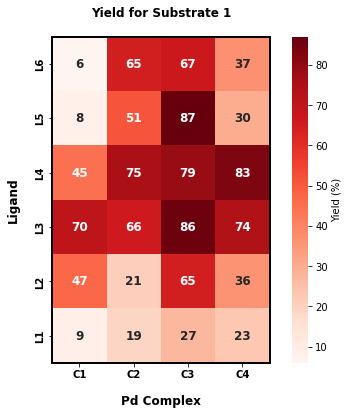

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Check current working directory
print("Current Working Directory:", os.getcwd())

# Load the Excel file
file_path = 'Substrate 1.xlsx'  # Update this path if necessary

# Check if the file exists
if os.path.exists(file_path):
    df = pd.read_excel(file_path)
    print("File loaded successfully!")
else:
    print(f"File not found: {file_path}")
    exit()  # Exit if the file is not found

# Check if required columns exist
required_columns = ['Ligand', 'Pd Complex', 'Yield']
if not all(col in df.columns for col in required_columns):
    print(f"Missing columns in the DataFrame. Required columns are: {required_columns}")
    exit()  # Exit if required columns are missing

# Extract numeric part and sort
df['Ligand_num'] = df['Ligand'].str.extract('(\d+)').astype(int)
df['Pd_Complex_num'] = df['Pd Complex'].str.extract('(\d+)').astype(int)
df.sort_values(['Ligand_num', 'Pd_Complex_num'], ascending=[False, True], inplace=True)

# Function to create and display a heatmap for Yield
def create_yield_heatmap(data, title, color, fmt):
    # Create pivot table for yield
    pivot_table = data.pivot("Ligand", "Pd Complex", "Yield").reindex(index=data['Ligand'].unique(), columns=data['Pd Complex'].unique())
    
    plt.figure(figsize=(8, 6))  # Adjust figure size if needed
    ax = sns.heatmap(pivot_table, annot=True, fmt=fmt, cmap=color, annot_kws={'weight': 'bold', 'size': 12},
                     cbar_kws={'label': 'Yield (%)'}, square=True)  # Use 'square=True' for uniform boxes

    # Formatting the heatmap
    ax.set_title(title, weight='bold', pad=20, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), weight='bold', labelpad=15, fontsize=12)
    ax.set_ylabel(ax.get_ylabel(), weight='bold', labelpad=15, fontsize=12)
    ax.set_xticklabels(ax.get_xticklabels(), weight='bold', fontsize=10)  # Adjust font size for x-axis labels
    ax.set_yticklabels(ax.get_yticklabels(), weight='bold', fontsize=10)  # Adjust font size for y-axis labels

    # Spines
    for _, spine in ax.spines.items():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(2)

    plt.show()
    return ax

# Create heatmap for Yield
ax = create_yield_heatmap(df, "Yield for Substrate 1", "Reds", "d")

# Function to save the plot
def save_plot(ax, file_name, dpi=500):
    ax.figure.savefig(file_name, dpi=dpi, bbox_inches='tight')

# Save the yield heatmap
save_plot(ax, "yield_heatmap.png")


Current Working Directory: /home/sigman/jupyter/Shubham-Deolka/Boronic acid
File loaded successfully!


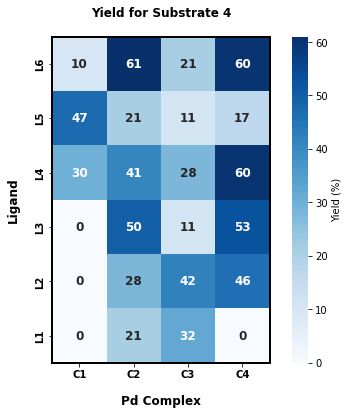

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Check current working directory
print("Current Working Directory:", os.getcwd())

# Load the Excel file
file_path = 'Substrate 4.xlsx'  # Update this path if necessary

# Check if the file exists
if os.path.exists(file_path):
    df = pd.read_excel(file_path)
    print("File loaded successfully!")
else:
    print(f"File not found: {file_path}")
    exit()  # Exit if the file is not found

# Check if required columns exist
required_columns = ['Ligand', 'Pd Complex', 'Yield']
if not all(col in df.columns for col in required_columns):
    print(f"Missing columns in the DataFrame. Required columns are: {required_columns}")
    exit()  # Exit if required columns are missing

# Extract numeric part and sort
df['Ligand_num'] = df['Ligand'].str.extract('(\d+)').astype(int)
df['Pd_Complex_num'] = df['Pd Complex'].str.extract('(\d+)').astype(int)
df.sort_values(['Ligand_num', 'Pd_Complex_num'], ascending=[False, True], inplace=True)

# Function to create and display a heatmap for Yield
def create_yield_heatmap(data, title, color, fmt):
    # Create pivot table for yield
    pivot_table = data.pivot("Ligand", "Pd Complex", "Yield").reindex(index=data['Ligand'].unique(), columns=data['Pd Complex'].unique())
    
    plt.figure(figsize=(8, 6))  # Adjust figure size if needed
    ax = sns.heatmap(pivot_table, annot=True, fmt=fmt, cmap=color, annot_kws={'weight': 'bold', 'size': 12},
                     cbar_kws={'label': 'Yield (%)'}, square=True)

    # Formatting the heatmap
    ax.set_title(title, weight='bold', pad=20, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), weight='bold', labelpad=15, fontsize=12)
    ax.set_ylabel(ax.get_ylabel(), weight='bold', labelpad=15, fontsize=12)
    ax.set_xticklabels(ax.get_xticklabels(), weight='bold', fontsize=10)  # Adjust font size for x-axis labels
    ax.set_yticklabels(ax.get_yticklabels(), weight='bold', fontsize=10)  # Adjust font size for y-axis labels

    # Spines
    for _, spine in ax.spines.items():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(2)

    plt.show()
    return ax

# Create heatmap for Yield with blue color
ax = create_yield_heatmap(df, "Yield for Substrate 4", "Blues", "d")

# Function to save the plot
def save_plot(ax, file_name, dpi=500):
    ax.figure.savefig(file_name, dpi=dpi, bbox_inches='tight')

# Save the yield heatmap
save_plot(ax, "yield_heatmap.png")


Current Working Directory: /home/sigman/jupyter/Shubham-Deolka/Boronic acid
File loaded successfully!


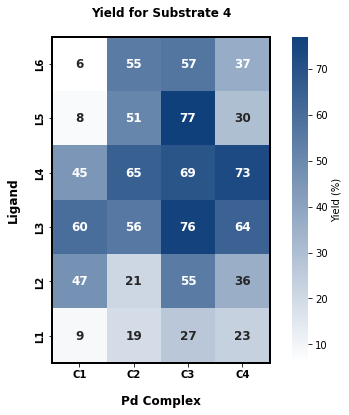

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import matplotlib.colors as mcolors

# Check current working directory
print("Current Working Directory:", os.getcwd())

# Load the Excel file
file_path = 'Substrate 1.xlsx'  # Update this path if necessary

# Check if the file exists
if os.path.exists(file_path):
    df = pd.read_excel(file_path)
    print("File loaded successfully!")
else:
    print(f"File not found: {file_path}")
    exit()  # Exit if the file is not found

# Check if required columns exist
required_columns = ['Ligand', 'Pd Complex', 'Yield']
if not all(col in df.columns for col in required_columns):
    print(f"Missing columns in the DataFrame. Required columns are: {required_columns}")
    exit()  # Exit if required columns are missing

# Extract numeric part and sort
df['Ligand_num'] = df['Ligand'].str.extract('(\d+)').astype(int)
df['Pd_Complex_num'] = df['Pd Complex'].str.extract('(\d+)').astype(int)
df.sort_values(['Ligand_num', 'Pd_Complex_num'], ascending=[False, True], inplace=True)

# Create a custom color map using the provided color code #10407B
custom_color_map = mcolors.LinearSegmentedColormap.from_list(
    'custom_blue', ['#FFFFFF', '#10407B'], N=256  # From white to your color
)

# Function to create and display a heatmap for Yield
def create_yield_heatmap(data, title, color_map, fmt):
    # Create pivot table for yield
    pivot_table = data.pivot("Ligand", "Pd Complex", "Yield").reindex(index=data['Ligand'].unique(), columns=data['Pd Complex'].unique())
    
    plt.figure(figsize=(8, 6))  # Adjust figure size if needed
    ax = sns.heatmap(pivot_table, annot=True, fmt=fmt, cmap=color_map, annot_kws={'weight': 'bold', 'size': 12},
                     cbar_kws={'label': 'Yield (%)'}, square=True)

    # Formatting the heatmap
    ax.set_title(title, weight='bold', pad=20, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), weight='bold', labelpad=15, fontsize=12)
    ax.set_ylabel(ax.get_ylabel(), weight='bold', labelpad=15, fontsize=12)
    ax.set_xticklabels(ax.get_xticklabels(), weight='bold', fontsize=10)  # Adjust font size for x-axis labels
    ax.set_yticklabels(ax.get_yticklabels(), weight='bold', fontsize=10)  # Adjust font size for y-axis labels

    # Spines
    for _, spine in ax.spines.items():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(2)

    plt.show()
    return ax

# Create heatmap for Yield with the custom color map
ax = create_yield_heatmap(df, "Yield for Substrate 4", custom_color_map, "d")

# Function to save the plot
def save_plot(ax, file_name, dpi=500):
    ax.figure.savefig(file_name, dpi=dpi, bbox_inches='tight')

# Save the yield heatmap
save_plot(ax, "yield_heatmap.png")


Current Working Directory: /home/sigman/jupyter/Shubham-Deolka/Boronic acid
File loaded successfully!


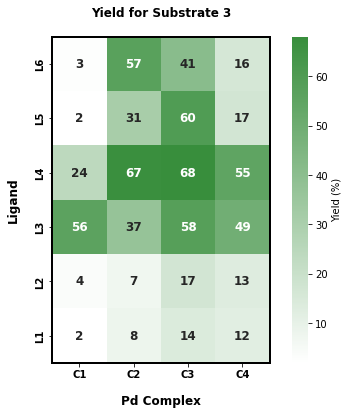

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import matplotlib.colors as mcolors

# Check current working directory
print("Current Working Directory:", os.getcwd())

# Load the Excel file
file_path = 'Substrate 3.xlsx'  # Update this path if necessary

# Check if the file exists
if os.path.exists(file_path):
    df = pd.read_excel(file_path)
    print("File loaded successfully!")
else:
    print(f"File not found: {file_path}")
    exit()  # Exit if the file is not found

# Check if required columns exist
required_columns = ['Ligand', 'Pd Complex', 'Yield']
if not all(col in df.columns for col in required_columns):
    print(f"Missing columns in the DataFrame. Required columns are: {required_columns}")
    exit()  # Exit if required columns are missing

# Extract numeric part and sort
df['Ligand_num'] = df['Ligand'].str.extract('(\d+)').astype(int)
df['Pd_Complex_num'] = df['Pd Complex'].str.extract('(\d+)').astype(int)
df.sort_values(['Ligand_num', 'Pd_Complex_num'], ascending=[False, True], inplace=True)

# Create a custom color map using the provided color code #4CAF50
custom_color_map = mcolors.LinearSegmentedColormap.from_list(
    'custom_green', ['#FFFFFF', '#388E3C'], N=256  # From white to your color
)

# Function to create and display a heatmap for Yield
def create_yield_heatmap(data, title, color_map, fmt):
    # Create pivot table for yield
    pivot_table = data.pivot("Ligand", "Pd Complex", "Yield").reindex(index=data['Ligand'].unique(), columns=data['Pd Complex'].unique())
    
    plt.figure(figsize=(8, 6))  # Adjust figure size if needed
    ax = sns.heatmap(pivot_table, annot=True, fmt=fmt, cmap=color_map, annot_kws={'weight': 'bold', 'size': 12},
                     cbar_kws={'label': 'Yield (%)'}, square=True)

    # Formatting the heatmap
    ax.set_title(title, weight='bold', pad=20, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), weight='bold', labelpad=15, fontsize=12)
    ax.set_ylabel(ax.get_ylabel(), weight='bold', labelpad=15, fontsize=12)
    ax.set_xticklabels(ax.get_xticklabels(), weight='bold', fontsize=10)  # Adjust font size for x-axis labels
    ax.set_yticklabels(ax.get_yticklabels(), weight='bold', fontsize=10)  # Adjust font size for y-axis labels

    # Spines
    for _, spine in ax.spines.items():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(2)

    plt.show()
    return ax

# Create heatmap for Yield with the custom color map
ax = create_yield_heatmap(df, "Yield for Substrate 3", custom_color_map, "d")

# Function to save the plot
def save_plot(ax, file_name, dpi=500):
    ax.figure.savefig(file_name, dpi=dpi, bbox_inches='tight')

# Save the yield heatmap
save_plot(ax, "yield_heatmap.png")


Current Working Directory: /home/sigman/jupyter/Shubham-Deolka/Boronic acid
File loaded successfully!


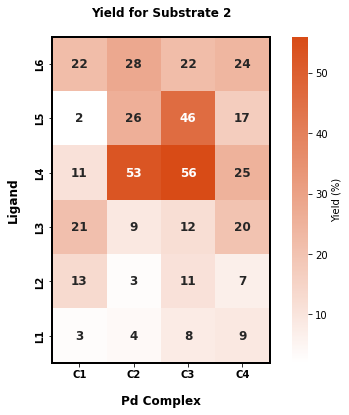

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import matplotlib.colors as mcolors

# Check current working directory
print("Current Working Directory:", os.getcwd())

# Load the Excel file
file_path = 'Substrate 2.xlsx'  # Update this path if necessary

# Check if the file exists
if os.path.exists(file_path):
    df = pd.read_excel(file_path)
    print("File loaded successfully!")
else:
    print(f"File not found: {file_path}")
    exit()  # Exit if the file is not found

# Check if required columns exist
required_columns = ['Ligand', 'Pd Complex', 'Yield']
if not all(col in df.columns for col in required_columns):
    print(f"Missing columns in the DataFrame. Required columns are: {required_columns}")
    exit()  # Exit if required columns are missing

# Extract numeric part and sort
df['Ligand_num'] = df['Ligand'].str.extract('(\d+)').astype(int)
df['Pd_Complex_num'] = df['Pd Complex'].str.extract('(\d+)').astype(int)
df.sort_values(['Ligand_num', 'Pd_Complex_num'], ascending=[False, True], inplace=True)

# Create a custom color map using the provided color code #FF7043
custom_color_map = mcolors.LinearSegmentedColormap.from_list(
    'custom_orange', ['#FFFFFF', '#D84B16'], N=256  # From white to your color
)

# Function to create and display a heatmap for Yield
def create_yield_heatmap(data, title, color_map, fmt):
    # Create pivot table for yield
    pivot_table = data.pivot("Ligand", "Pd Complex", "Yield").reindex(index=data['Ligand'].unique(), columns=data['Pd Complex'].unique())
    
    plt.figure(figsize=(8, 6))  # Adjust figure size if needed
    ax = sns.heatmap(pivot_table, annot=True, fmt=fmt, cmap=color_map, annot_kws={'weight': 'bold', 'size': 12},
                     cbar_kws={'label': 'Yield (%)'}, square=True)

    # Formatting the heatmap
    ax.set_title(title, weight='bold', pad=20, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), weight='bold', labelpad=15, fontsize=12)
    ax.set_ylabel(ax.get_ylabel(), weight='bold', labelpad=15, fontsize=12)
    ax.set_xticklabels(ax.get_xticklabels(), weight='bold', fontsize=10)  # Adjust font size for x-axis labels
    ax.set_yticklabels(ax.get_yticklabels(), weight='bold', fontsize=10)  # Adjust font size for y-axis labels

    # Spines
    for _, spine in ax.spines.items():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(2)

    plt.show()
    return ax

# Create heatmap for Yield with the custom color map
ax = create_yield_heatmap(df, "Yield for Substrate 2", custom_color_map, "d")

# Function to save the plot
def save_plot(ax, file_name, dpi=500):
    ax.figure.savefig(file_name, dpi=dpi, bbox_inches='tight')

# Save the yield heatmap
save_plot(ax, "yield_heatmap.png")
